<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and assumptions](README.md)

# 01 · A pooled slope can hide the within-site relationship

Two sites operate at different input levels and have different response baselines. If we pool their observations, does the regression slope describe the relationship within either site? We will fit the same rows twice through the real statsmodels worker: first with input alone, then with input and a categorical site term. SQL will reconstruct predictions and independently recover the adjusted slope by removing each site's mean.

**All observations are synthetic teaching data**, generated locally from a fixed random seed. There are no external measurements, private records, live APIs or replay modes. The generating equation is disclosed below. Confidence intervals describe a fitted statistical model under its assumptions; a precise estimate from a misspecified model can still answer the wrong question.

## Change the difference between site baselines

`SITE_OFFSET` is a finite number from **0 to 40 response units**, default **30**. It adds that amount to site B's response at every input value. The experiment uses **10**. Input positions, site membership and the 120 seeded noise draws stay fixed. This is a controlled change to a synthetic generator, not an intervention on observed people or equipment.

Each site has 60 rows. Site A's input spans 2–12 hours; site B's spans 8–18 hours, so the ranges partly overlap. Both share a generating slope of **−1.5 response units per hour**; errors are independently drawn from a normal distribution with standard deviation **2 response units**, seed **1729**. Restart Kernel → Run All after editing.

In [1]:
SITE_OFFSET = 30.0  # Response units added to site B; experiment: 10.0

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

assert type(SITE_OFFSET) in {int, float} and np.isfinite(SITE_OFFSET) and 0 <= SITE_OFFSET <= 40
noise = pd.DataFrame({"row_id": np.arange(120), "noise": np.random.default_rng(1729).normal(0, 2, 120)})
noise_fingerprint = hashlib.sha256(noise.to_json(orient="records", double_precision=15).encode()).hexdigest()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Synthetic two-site data · seed 1729 · site B offset {SITE_OFFSET:g} response units · ordinary OLS, conditional inference",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.92))
    plt.show()


con = haybarn.connect()
con.register("noise_input", noise)
con.execute("CREATE TABLE noise_draws AS SELECT * FROM noise_input")
con.unregister("noise_input")
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-statsmodels/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-statsmodels/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-statsmodels/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-statsmodels/notebooks/pyproject.toml.

## Make the generator and common analysis population explicit

The literal tagged Git launch runs from this notebook directory alone. SQL turns the seeded noise into the declared measurements. We check missingness and row counts before fitting: formula libraries may otherwise drop missing rows, making two models appear comparable when their populations differ. Input is hours and response is an arbitrary measurement unit; the model has an intercept by default.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'statsmodels' (
 TYPE vgi,
 LOCATION 'uvx --python 3.14 --from git+https://github.com/Query-farm/vgi-statsmodels.git@v0.4.0 --constraints worker-constraints.txt vgi-statsmodels'
);
CREATE TABLE measurements AS
WITH design AS (
 SELECT row_id,CASE WHEN row_id<60 THEN 'A' ELSE 'B' END AS site,
 2.0+10.0*(row_id%60)/59.0+CASE WHEN row_id>=60 THEN 6.0 ELSE 0 END AS x,
 noise FROM noise_draws
)
SELECT *,20.0-1.5*x+CASE WHEN site='B' THEN {{SITE_OFFSET}} ELSE 0 END+noise AS y
FROM design;

,Count


In [4]:
%%sql coverage <<
SELECT site,count(*) AS observations,min(x) AS min_hours,max(x) AS max_hours,
 avg(x) AS mean_hours,avg(y) AS mean_response,
 count(*) FILTER(WHERE x IS NULL OR y IS NULL OR site IS NULL OR NOT isfinite(x) OR NOT isfinite(y)) AS unavailable
FROM measurements GROUP BY site ORDER BY site;

In [5]:
display(coverage)
assert coverage.observations.sum() == len(noise) and coverage.unavailable.sum() == 0
assert coverage.site.tolist() == ["A", "B"] and coverage.observations.min() > 2
assert con.execute("SELECT count(DISTINCT row_id)=count(*) FROM measurements").fetchone()[0]
prose(
    f"Both specifications receive **{coverage.observations.sum()} complete observations**. Site B's mean input is **{coverage.mean_hours.iloc[1] - coverage.mean_hours.iloc[0]:.1f} hours higher** than site A's; its mean response is **{coverage.mean_response.iloc[1] - coverage.mean_response.iloc[0]:+.2f} units different** at this offset. That joint shift can influence a pooled slope. Seeded-noise fingerprint: `{noise_fingerprint}`."
)

,site,observations,min_hours,max_hours,mean_hours,mean_response,unavailable
0,A,60,2.0,12.0,7.0,9.298725,0
1,B,60,8.0,18.0,13.0,30.686777,0


Both specifications receive **120 complete observations**. Site B's mean input is **6.0 hours higher** than site A's; its mean response is **+21.39 units different** at this offset. That joint shift can influence a pooled slope. Seeded-noise fingerprint: `ebd6f42b92a6ba5f35aa171234e2668ae2355f5affcd4bd8173a92a823662eb9`.

## Fit two questions on the same rows

`y ~ x` estimates one pooled line. `y ~ x + C(site)` estimates parallel site-specific lines with a shared slope; site A is the reference and `C(site)[T.B]` is B's intercept difference. The adjusted model assumes the slope is common to both sites; it does not test that assumption merely by fitting it.

These buffering table functions consume the complete input relation. We materialize coefficient and model-statistic results before capturing local SELECTs, so displaying a DataFrame does not repeat a fit. `ols` and `model_stats` independently refit the same specified model; there is no shared fitted-model object.

In [6]:
%%sql
CREATE TABLE coefficients AS
SELECT 'Pooled' AS model,* FROM statsmodels.ols((SELECT x,y,site FROM measurements ORDER BY row_id),formula := 'y ~ x')
UNION ALL
SELECT 'Site-adjusted' AS model,* FROM statsmodels.ols((SELECT x,y,site FROM measurements ORDER BY row_id),formula := 'y ~ x + C(site)');
CREATE TABLE statistics AS
SELECT 'Pooled' AS model,* FROM statsmodels.model_stats((SELECT x,y,site FROM measurements ORDER BY row_id),formula := 'y ~ x')
UNION ALL
SELECT 'Site-adjusted' AS model,* FROM statsmodels.model_stats((SELECT x,y,site FROM measurements ORDER BY row_id),formula := 'y ~ x + C(site)');
CREATE TABLE fitted AS
WITH terms AS (
 SELECT model,max(coef) FILTER(WHERE term='Intercept') AS intercept,
 max(coef) FILTER(WHERE term='x') AS slope,
 coalesce(max(coef) FILTER(WHERE term='C(site)[T.B]'),0) AS site_shift
 FROM coefficients GROUP BY model
)
SELECT m.*,t.model,t.intercept+t.slope*m.x+CASE WHEN m.site='B' THEN t.site_shift ELSE 0 END AS prediction
FROM measurements m CROSS JOIN terms t;

,Count


In [7]:
%%sql coefficients <<
SELECT * FROM coefficients ORDER BY model,term;

In [8]:
%%sql fit_stats <<
SELECT model,max(value) FILTER(WHERE statistic='nobs') AS nobs,
 max(value) FILTER(WHERE statistic='df_resid') AS df_resid,
 max(value) FILTER(WHERE statistic='r_squared') AS r_squared,
 max(value) FILTER(WHERE statistic='adj_r_squared') AS adjusted_r_squared,
 max(value) FILTER(WHERE statistic='aic') AS aic
FROM statistics GROUP BY model ORDER BY model;

In [9]:
display(coefficients)
display(fit_stats)
assert set(coefficients.query("model=='Site-adjusted'").term) == {"Intercept", "x", "C(site)[T.B]"}
assert (fit_stats.nobs == len(noise)).all()
assert np.allclose(coefficients.t_value, coefficients.coef / coefficients.std_err)
assert coefficients.p_value.between(0, 1).all()
assert (coefficients.ci_lower <= coefficients.coef).all() and (
    coefficients.coef <= coefficients.ci_upper
).all()
slopes = coefficients.query("term=='x'").set_index("model")
prose(
    f"The pooled slope is **{slopes.loc['Pooled', 'coef']:+.3f} units/hour**; the site-adjusted slope is **{slopes.loc['Site-adjusted', 'coef']:+.3f} units/hour**. {'Their signs differ: pooling reverses the within-site direction in this constructed example.' if np.sign(slopes.loc['Pooled', 'coef']) != np.sign(slopes.loc['Site-adjusted', 'coef']) else 'Their signs agree at this offset, but the pooled and within-site estimates still answer different questions.'} A small p-value tests a zero coefficient under that model; it is not the probability that the model is correct or that the association is causal."
)

,model,term,coef,std_err,t_value,p_value,ci_lower,ci_upper
0,Pooled,Intercept,9.074582,2.558498,3.546840,5.602794e-04,4.008060,14.141104
1,Pooled,x,1.091817,0.235913,4.628046,9.546543e-06,0.624645,1.558989
2,Site-adjusted,C(site)[T.B],30.335892,0.470259,64.508950,2.702225e-93,29.404569,31.267214
3,Site-adjusted,Intercept,19.737872,0.455919,43.292453,7.413564e-74,18.834947,20.640796
4,Site-adjusted,x,-1.491307,0.056022,-26.620217,1.804021e-51,-1.602254,-1.380359


,model,nobs,df_resid,r_squared,adjusted_r_squared,aic
0,Pooled,120.0,118.0,0.153629,0.146457,914.653119
1,Site-adjusted,120.0,117.0,0.976855,0.976459,484.753733


The pooled slope is **+1.092 units/hour**; the site-adjusted slope is **-1.491 units/hour**. Their signs differ: pooling reverses the within-site direction in this constructed example. A small p-value tests a zero coefficient under that model; it is not the probability that the model is correct or that the association is causal.

## See what each line is fitting

The pooled line uses both sites together. The colored adjusted lines use a common slope and separate intercepts; each is drawn only across its site's observed input range. The fixed-seed simulation has a known within-site relationship. Real data would require a substantive reason to adjust for site, checks for differing slopes and other omitted variables, and an appropriate design before causal interpretation.

In [10]:
%%sql predictions <<
SELECT * FROM fitted ORDER BY model,site,x;

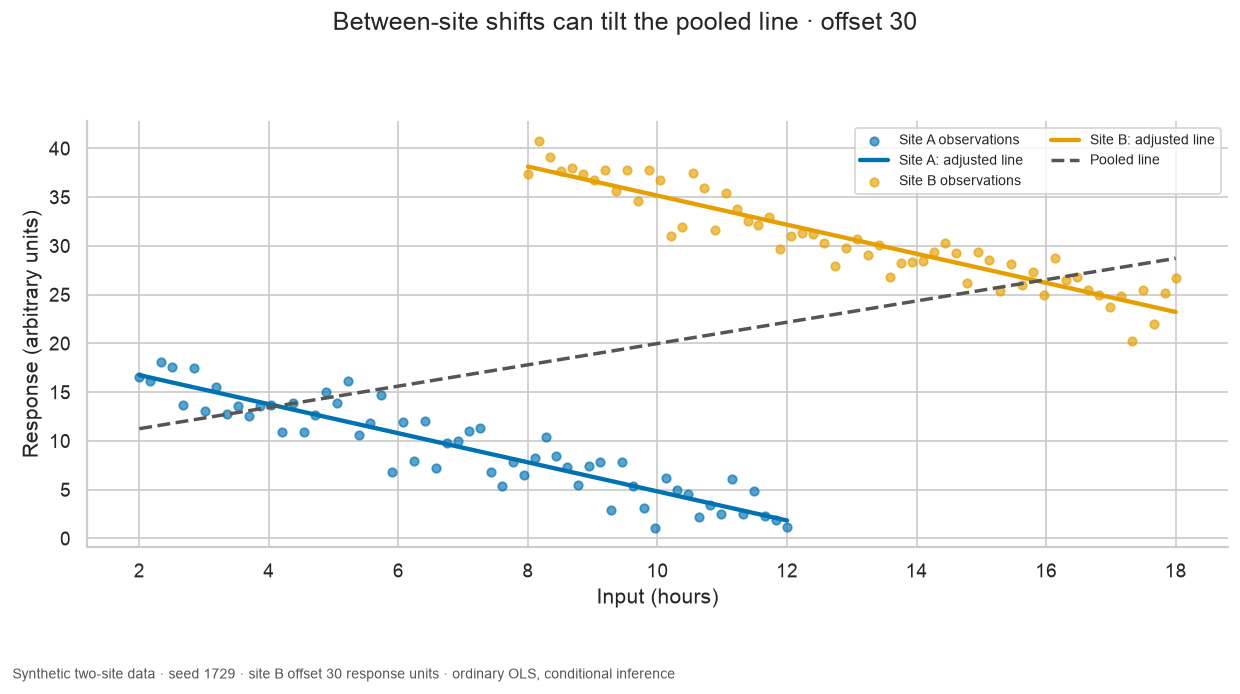

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = {"A": "#0072b2", "B": "#e69f00"}
for site in ["A", "B"]:
    rows = predictions.loc[(predictions.site == site) & (predictions.model == "Site-adjusted")]
    ax.scatter(rows.x, rows.y, color=colors[site], alpha=0.65, s=24, label=f"Site {site} observations")
    ax.plot(rows.x, rows.prediction, color=colors[site], lw=2.5, label=f"Site {site}: adjusted line")
pooled = predictions.loc[predictions.model == "Pooled"].sort_values("x")
ax.plot(pooled.x, pooled.prediction, color="#555555", ls="--", lw=2, label="Pooled line")
ax.set(xlabel="Input (hours)", ylabel="Response (arbitrary units)")
ax.legend(ncol=2, fontsize=8, loc="best")
fig.suptitle(f"Between-site shifts can tilt the pooled line · offset {SITE_OFFSET:g}")
finish(fig)

## Recover the adjusted slope without refitting a regression library

Subtract each site's mean from both x and y. The ratio `sum(x_within*y_within)/sum(x_within²)` is the common within-site slope for this additive site-intercept model. The ordinary pooled slope uses global centering instead. Separately, reconstruct residual sums of squares and R² from the worker's coefficients and compare them with `model_stats`.

The adjusted ordinary standard error for x is `sqrt((SSE / residual_df) / sum(x_within²))`; the pooled counterpart uses globally centered x. These are classical, constant-variance OLS standard errors. They do not account for heteroskedasticity or within-site dependence. The worker calls ordinary `OLS.fit()` and does not expose a robust covariance option here. [statsmodels fit documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.fit.html).

In [12]:
%%sql verification <<
WITH centered AS (
 SELECT x-avg(x) OVER() AS x_global,y-avg(y) OVER() AS y_global,
 x-avg(x) OVER(PARTITION BY site) AS x_within,
 y-avg(y) OVER(PARTITION BY site) AS y_within FROM measurements
), algebra AS (
 SELECT 'Pooled' AS model,sum(x_global*y_global)/sum(x_global*x_global) AS sql_slope,
 sum(x_global*x_global) AS centered_x_ss FROM centered
 UNION ALL
 SELECT 'Site-adjusted',sum(x_within*y_within)/sum(x_within*x_within),sum(x_within*x_within) FROM centered
), residuals AS (
 SELECT model,sum(pow(y-prediction,2)) AS sse,avg(y-prediction) AS mean_residual,
 sum((y-prediction)*x) AS residual_x_moment FROM fitted GROUP BY model
), degrees AS (
 SELECT model,max(value) FILTER(WHERE statistic='df_resid') AS df_resid,
 max(value) FILTER(WHERE statistic='r_squared') AS worker_r_squared FROM statistics GROUP BY model
)
SELECT a.model,sql_slope,c.coef AS worker_slope,sse,mean_residual,residual_x_moment,
 1-sse/(SELECT sum(y_global*y_global) FROM centered) AS sql_r_squared,worker_r_squared,
 sqrt(sse/df_resid/centered_x_ss) AS sql_std_err,c.std_err AS worker_std_err
FROM algebra a JOIN residuals USING(model) JOIN degrees USING(model)
JOIN coefficients c ON c.model=a.model AND c.term='x' ORDER BY a.model;

In [13]:
display(verification)
assert np.allclose(verification.sql_slope, verification.worker_slope, rtol=1e-10, atol=1e-10)
assert np.allclose(verification.sql_r_squared, verification.worker_r_squared, rtol=1e-10, atol=1e-10)
assert np.allclose(verification.sql_std_err, verification.worker_std_err, rtol=1e-10, atol=1e-10)
assert np.allclose(verification.mean_residual, 0, atol=1e-10)
assert np.allclose(verification.residual_x_moment, 0, atol=1e-8)
assert np.allclose(fit_stats.df_resid, fit_stats.nobs - [2, 3])
prose(
    "The SQL slope, residual R² and classical standard error agree with the worker for both models. Zero mean residual and zero residual–input moment check the normal equations. Higher in-sample R² after adding a site term is not evidence of better forecasting: no held-out evaluation is performed, and adding predictors cannot increase OLS training SSE on the same rows."
)

,model,sql_slope,worker_slope,sse,mean_residual,residual_x_moment,sql_r_squared,worker_r_squared,sql_std_err,worker_std_err
0,Pooled,1.091817,1.091817,13882.587909,4.204045e-15,2.323475e-12,0.153629,0.153629,0.235913,0.235913
1,Site-adjusted,-1.491307,-1.491307,379.642157,-4.212926e-14,-5.785239e-11,0.976855,0.976855,0.056022,0.056022


The SQL slope, residual R² and classical standard error agree with the worker for both models. Zero mean residual and zero residual–input moment check the normal equations. Higher in-sample R² after adding a site term is not evidence of better forecasting: no held-out evaluation is performed, and adding predictors cannot increase OLS training SSE on the same rows.

## Precision is conditional on the specification

The horizontal intervals are the worker's **95% coefficient confidence intervals**, using the ordinary OLS t-based calculation. They are neither prediction intervals for individual responses nor a 95% probability statement about a fixed coefficient. The generating slope is shown because it is known in this simulation; it is not normally available in observational data. [statsmodels interval documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.conf_int.html).

Independent, mean-zero errors with constant variance and a correctly specified linear mean justify the classical inference used here; normal errors support its finite-sample t calculation. The adjusted generator meets those design assumptions. The pooled specification omits the site offset, so its displayed interval does not repair that omission.

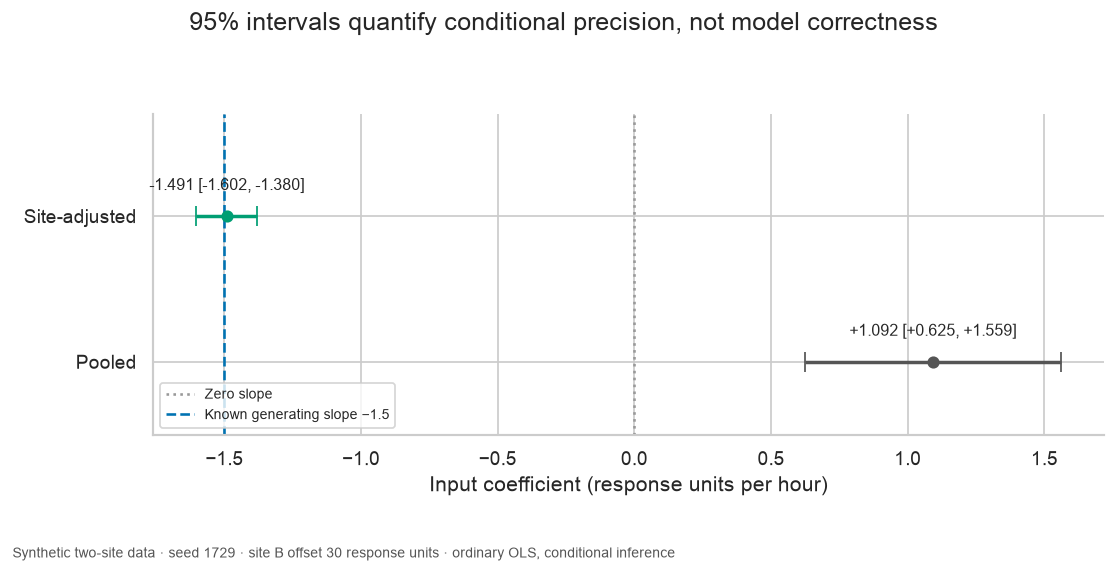

The adjusted estimate is **-1.491**, compared with the generating slope **−1.500 units/hour**. Its 95% interval is **[-1.602, -1.380]**. Whether a particular seeded interval contains the true slope is not a test of 95% long-run coverage; that would require a separate repeated-sampling study.

3327

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (name, color) in enumerate([("Pooled", "#555555"), ("Site-adjusted", "#009e73")]):
    row = slopes.loc[name]
    ax.errorbar(
        row.coef,
        i,
        xerr=[[row.coef - row.ci_lower], [row.ci_upper - row.coef]],
        fmt="o",
        color=color,
        capsize=6,
        lw=2,
    )
    ax.annotate(
        f"{row.coef:+.3f} [{row.ci_lower:+.3f}, {row.ci_upper:+.3f}]",
        (row.coef, i),
        xytext=(0, 15),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
ax.axvline(0, color="#999999", ls=":", label="Zero slope")
ax.axvline(-1.5, color="#0072b2", ls="--", label="Known generating slope −1.5")
ax.set(
    yticks=[0, 1],
    yticklabels=["Pooled", "Site-adjusted"],
    ylim=(-0.5, 1.7),
    xlabel="Input coefficient (response units per hour)",
)
ax.legend(loc="lower left", fontsize=8)
fig.suptitle("95% intervals quantify conditional precision, not model correctness")
finish(fig)
prose(
    f"The adjusted estimate is **{slopes.loc['Site-adjusted', 'coef']:+.3f}**, compared with the generating slope **−1.500 units/hour**. Its 95% interval is **[{slopes.loc['Site-adjusted', 'ci_lower']:+.3f}, {slopes.loc['Site-adjusted', 'ci_upper']:+.3f}]**. Whether a particular seeded interval contains the true slope is not a test of 95% long-run coverage; that would require a separate repeated-sampling study."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "site_offset": SITE_OFFSET,
            "noise_fingerprint": noise_fingerprint,
            "coefficients": coefficients.to_dict(orient="records"),
            "statistics": fit_stats.to_dict(orient="records"),
            "verification": verification.to_dict(orient="records"),
            "coverage": coverage.to_dict(orient="records"),
        },
        indent=2,
    )
)

## Experiment: reduce the site offset

Change only `SITE_OFFSET` from **30.0 to 10.0**. Predict that the pooled slope moves because the between-site response difference shrinks. The adjusted slope, its standard error and its interval should stay unchanged to numerical precision: the categorical site term absorbs a constant shift applied to every site-B response. Site B's coefficient should fall by exactly **20 response units**. Compare both charts, coefficient tables and the seeded-noise fingerprint. Restore **30.0** afterwards.

This controlled generator illustrates omitted-variable distortion. It does not show that adding every available covariate improves an analysis, that a small p-value establishes causation, or that a fitted model has been validated for deployment.

In [15]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)